# Where the Starting Structure Comes From

*The Mathematics of Machine Intelligence · Chapter 26*

Find a starting design by search, and see what choosing can and cannot do without people.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask who supplied the candidates, who said which was good, and whether the test that picked the winner is separate from the test that reports it. Use the odds card for how hard a single good setting is to find, the choosing-and-copying split to see whether a change came from reweighting what was there or from new variation, and the replicator card to check whether the best kind was in the pool at all. Report the score with the size of the test and the choices people made.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 26, Where the Starting Structure Comes From: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels(ratios=None):
    kwargs = {'gridspec_kw': {'width_ratios': ratios}} if ratios else {}
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained', **kwargs)
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
WIRINGS = 2 ** 20

def find_probability(open_switches, tries):
    """Chance that at least one of `tries` random settings of the open switches is the good wiring.

    Assumes the creature's fixed genes are all right, so one try succeeds with chance 2^(-open_switches)."""
    return 1.0 - (1.0 - 2.0 ** (-open_switches)) ** tries
OPEN_SWITCHES = [5, 10, 15, 20]
TRIES = [1, 10, 100, 1000, 10000]

def odds_picture(open_switches=10, tries=1000):
    k = open_switches
    p = find_probability(k, tries)
    fig, ax = panels()
    grid = np.unique(np.round(np.logspace(0, 4, 60)).astype(int))
    ax[0].plot(grid, [find_probability(k, int(g)) for g in grid], color=TEAL)
    ax[0].plot([tries], [p], marker='o', color=NAVY, markersize=9, zorder=5)
    ax[0].axvline(1000, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[0], 1000, 1.03, '1,000 tries', fontsize=9, va='bottom')
    ax[0].set(xscale='log', yscale='log', ylim=(1e-07, 2.5), xlim=(1, 12000), xlabel='random tries in a lifetime', ylabel='chance of finding the good wiring', title=f'{k} open switches, others right')
    tag(ax[0], 60, max(p, 2e-07) * 6 if p < 0.3 else 0.3, f'{sig(p)} at {tries:,} tries', fontsize=9)
    for kk, color in zip(OPEN_SWITCHES, [NAVY, DARK_GOLD, TEAL, TERRA]):
        ax[1].plot(grid, [find_probability(kk, int(g)) for g in grid], color=color, linewidth=2.6 if kk == k else 1.1, alpha=1 if kk == k else 0.6, label=f'{kk} open')
    ring(ax[1], tries, p)
    ax[1].set(xscale='log', yscale='log', ylim=(1e-07, 2.5), xlim=(1, 12000), xlabel='random tries in a lifetime', ylabel='chance of finding it', title='Every case, selected one ringed')
    ax[1].legend(fontsize=9, loc='lower right', title='open switches', title_fontsize=9)
    metrics = {'Chance of finding it': sig(p), 'Settings of the open switches': f'{2 ** k:,}', 'Tries for even odds': f'{math.ceil(math.log(0.5) / math.log(1 - 2.0 ** (-k))):,}', 'Wirings in all (20 switches)': f'{WIRINGS:,}'}
    summary = f"A creature with {k} open switches and all its fixed genes right finds the good wiring in up to {tries:,} tries with chance {sig(p)}. The chapter's two cases are 10 open switches (about 62 in 100) and 20 (under 1 in 1,000) at 1,000 tries."
    calc = f'P = 1 - (1 - 2^(-{k}))^{tries} = 1 - (1 - {sig(2.0 ** (-k), 4)})^{tries} = {sig(p)}. One random try on 20 switches succeeds with chance 2^(-20) = {sig(2.0 ** (-20), 3)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
GENES, POP = (20, 1000)
ONE, ZERO, OPEN = (1, 0, 2)

def initial_population(rng):
    """Each gene is 1 a quarter of the time, 0 a quarter and ? half the time."""
    return rng.choice(np.array([ONE, ZERO, OPEN], dtype=np.int8), size=(POP, GENES), p=[0.25, 0.25, 0.5])

def fitness_weights(genes, tries, rng):
    """1 + 19 n / G, where n is the number of the G trials left after the good wiring is found; 1 if never found.

    A creature with a 0 gene can never find it. With k open switches the trial that first succeeds is geometric with chance 2^(-k)."""
    wrong = (genes == ZERO).any(axis=1)
    k = (genes == OPEN).sum(axis=1)
    first_success = rng.geometric(2.0 ** (-k))
    found = ~wrong & (first_success <= tries)
    return np.where(found, 1.0 + 19.0 * (tries - first_success) / tries, 1.0)

def next_generation(genes, weights, rng):
    """Parents drawn in proportion to weight; one child per pair by single-point crossover; no mutation."""
    n = len(genes)
    cumulative = np.cumsum(weights)
    picks = np.minimum(np.searchsorted(cumulative, rng.random(2 * n) * cumulative[-1]), n - 1)
    first, second = (genes[picks[:n]], genes[picks[n:]])
    cut = rng.integers(1, GENES, size=n)
    take_first = np.arange(GENES)[None, :] < cut[:, None]
    return np.where(take_first, first, second)

def allele_shares(genes):
    return [float((genes == code).mean()) for code in (ONE, ZERO, OPEN)]

@lru_cache(maxsize=None)
def typical_run(seed, generations=50, tries=1000):
    """Shares of 1, 0 and ? alleles, and the mean number of open switches, from generation 0 to `generations`."""
    rng = np.random.default_rng([26, seed])
    genes = initial_population(rng)
    rows = []
    for _ in range(generations + 1):
        rows.append(allele_shares(genes) + [float((genes == OPEN).sum(axis=1).mean())])
        genes = next_generation(genes, fitness_weights(genes, tries, rng), rng)
    return np.array(rows)
SEEDS = [1, 2, 3, 4, 5, 6, 7, 8]

def baldwin_picture(seed=1):
    run = typical_run(seed)
    gens = np.arange(run.shape[0])
    fig, ax = panels()
    for col, name, color in ((0, '1 (connection built)', TEAL), (1, '0 (connection left out)', TERRA), (2, '? (left to learn)', GOLD)):
        ax[0].plot(gens, run[:, col], color=color, label=name)
    ax[0].legend(fontsize=8.5, loc='center right')
    ax[0].set(xlabel='generation', ylabel='share of gene copies', ylim=(0, 1), xlim=(0, 50), title=f'Seeded run {seed}')
    for s in SEEDS:
        r = typical_run(s)
        ax[1].plot(gens, r[:, 0], color=NAVY if s == seed else TEAL, linewidth=2.8 if s == seed else 1.0, alpha=1 if s == seed else 0.5)
    ax[1].set(xlabel='generation', ylabel='share of gene copies that are 1', ylim=(0, 1), xlim=(0, 50), title='All eight seeds, selected one dark')
    metrics = {'Share of 1 at generation 50': sig(run[50, 0]), 'Share of 0 at generation 50': sig(run[50, 1]), 'Share of ? at generation 50': sig(run[50, 2]), 'Open switches per creature, start to end': f'{sig(run[0, 3])} to {sig(run[50, 3])}'}
    summary = f'In seeded run {seed}, the share of 1 genes goes from {sig(run[0, 0])} to {sig(run[50, 0])} in 50 generations and the share of 0 genes from {sig(run[0, 1])} to {sig(run[50, 1])}, with no learned setting ever written into a gene. Many ? genes remain, so the good wiring is not yet inherited.'
    calc = 'Each creature draws its first successful trial from a geometric law with chance 2^(-open switches), or never succeeds if any gene is 0. Parent weight = 1 + 19 n / 1000, n the trials left. Single-point crossover, no mutation, 1,000 creatures, 20 genes.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
REPORTED_FIXATION = 0.167
FIX_TRIES = [30, 100, 300, 1000, 3000]
FIX_RUNS = 200
GENERATION_CAP = 20000

def classify_population(genes):
    """'success' if every creature carries 1 at every gene, 'fail' if some gene is fixed on a wrong or open setting, else None."""
    fixed = (genes == genes[0]).all(axis=0)
    if not fixed.any():
        return None
    if (genes[0][fixed] != ONE).any():
        return 'fail'
    return 'success' if fixed.all() else None

def fixation_run(seed, tries, cap=GENERATION_CAP):
    rng = np.random.default_rng([2600, seed, tries])
    genes = initial_population(rng)
    for generation in range(cap):
        outcome = classify_population(genes)
        if outcome:
            return (outcome, generation)
        genes = next_generation(genes, fitness_weights(genes, tries, rng), rng)
    return ('unfinished', cap)

@lru_cache(maxsize=None)
def fixation_table(tries, runs=FIX_RUNS):
    outcomes = [fixation_run(s, tries) for s in range(runs)]
    count = lambda name: sum((o == name for o, _ in outcomes))
    return {'success': count('success'), 'fail': count('fail'), 'unfinished': count('unfinished'), 'runs': runs, 'mean_generations': float(np.mean([g for _, g in outcomes]))}

def wilson_interval(successes, n, z=1.96):
    """Wilson score interval for a proportion."""
    p = successes / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return (centre - half, centre + half)

def fixation_picture(tries=1000):
    table = fixation_table(tries)
    runs = table['runs']
    share = table['success'] / runs
    lo, hi = wilson_interval(table['success'], runs)
    fig, ax = panels()
    counts = [table['success'], table['fail'], table['unfinished']]
    bars = ax[0].bar(range(3), counts, color=[TEAL, TERRA, GREY], width=0.6)
    for b, v in zip(bars, counts):
        tag(ax[0], b.get_x() + b.get_width() / 2, v + runs * 0.02, str(v), va='bottom', fontsize=11)
    ax[0].set_xticks(range(3))
    ax[0].set_xticklabels(['right wiring\nfixed', 'wrong or open\nsetting fixed', 'unfinished'], fontsize=9)
    ax[0].set(ylabel=f'runs, of {runs}', ylim=(0, runs * 1.08), title=f'How {runs} seeded runs ended, {tries:,} tries')
    shares = []
    for t in FIX_TRIES:
        tt = fixation_table(t)
        a, b = wilson_interval(tt['success'], tt['runs'])
        p = tt['success'] / tt['runs']
        shares.append(p)
        ax[1].errorbar([t], [p], yerr=[[p - a], [b - p]], color=NAVY if t == tries else TEAL, marker='o', markersize=7, capsize=3, linewidth=1.6)
    ax[1].plot(FIX_TRIES, shares, color=TEAL, linewidth=1, alpha=0.6, zorder=0)
    ax[1].plot([1000], [REPORTED_FIXATION], marker='*', color=DARK_GOLD, markersize=14, linestyle='none', zorder=7, label='reported: 0.167')
    ring(ax[1], tries, share)
    ax[1].legend(fontsize=9, loc='upper left')
    ax[1].set(xscale='log', xlabel='trials per lifetime', ylabel='share of runs where the right wiring fixed', ylim=(-0.02, 0.62), title='Every budget, with 95 percent intervals')
    metrics = {'Right wiring fixed': f"{table['success']} of {runs}", 'Share (95 percent interval)': f'{sig(share, 2)} ({sig(lo, 2)} to {sig(hi, 2)})', 'Mean generations per run': f"{table['mean_generations']:.0f}", 'Reported at 1,000 tries': '0.167 (16.7 percent)'}
    summary = f"With {tries:,} trials per lifetime, the right wiring fixed in {table['success']} of {runs} seeded runs, a share of {sig(share, 2)}. The chapter reports 0.167 at 1,000 trials for Fontanari and Santos; this reimplementation is not their code, so close agreement is not claimed."
    if tries == 1000 and (not lo <= REPORTED_FIXATION <= hi):
        summary += ' The interval excludes 0.167: this run does not reproduce that share.'
    calc = f"Share = {table['success']} / {runs} = {sig(share, 3)}. 95 percent Wilson interval {sig(lo, 3)} to {sig(hi, 3)}, which treats the runs as independent."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TRAITS = np.array([0.0, 1.0, 2.0, 3.0])
OFFSPRING_BASE = np.array([1.0, 1.0, 2.0])

def price_split(shift_d, offspring_d):
    """Split the change in average trait into choosing, Cov(w, z) / mean(w), and copying, E(w dz) / mean(w).

    Seeds A to D have traits 0, 1, 2, 3 mm and leave 1, 1, 2 and `offspring_d` seedlings; D's seedlings differ from D by `shift_d`."""
    w = np.append(OFFSPRING_BASE, offspring_d)
    z = TRAITS
    dz = np.array([0.0, 0.0, 0.0, shift_d])
    w_bar = w.mean()
    choosing = ((w * z).mean() - w_bar * z.mean()) / w_bar
    copying = (w * dz).mean() / w_bar
    return (choosing, copying, choosing + copying)
SHIFTS = [-0.9, -0.6, -0.3, 0.0, 0.3, 0.6]
D_OFFSPRING = [2, 3, 4]

def price_picture(shift_d=-0.3, offspring_d=2):
    choosing, copying, net = price_split(shift_d, offspring_d)
    fig, ax = panels()
    ys = [2, 1, 0]
    vals = [choosing, copying, net]
    names = ['choosing', 'copying', 'net change']
    for y, v, c in zip(ys, vals, [TEAL, TERRA, NAVY]):
        ax[0].barh(y, v, color=c, height=0.55)
        tag(ax[0], v + (0.025 if v >= 0 else -0.025), y, f'{v:+.3f}'.replace('+0.000', '0'), ha='left' if v >= 0 else 'right', fontsize=10)
    ax[0].axvline(0, color=GREY, linewidth=1)
    ax[0].set_yticks(ys)
    ax[0].set_yticklabels(names)
    ax[0].set(xlim=(-0.7, 1.35), xlabel='change in the average hook length (mm)', title='Two parts that add up exactly')
    grid = np.linspace(-1.0, 0.8, 50)
    for od, color in zip(D_OFFSPRING, [NAVY, TEAL, DARK_GOLD]):
        ax[1].plot(grid, [price_split(s, od)[2] for s in grid], color=color, linewidth=2.6 if od == offspring_d else 1.1, alpha=1 if od == offspring_d else 0.6, label=f'D leaves {od} seedlings')
    ring(ax[1], shift_d, net)
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].legend(fontsize=9, loc='upper right')
    ax[1].set(xlabel="change in D's seedlings (mm)", ylabel='net change in average hook (mm)', ylim=(-0.2, 1.45), title='Every case, selected one ringed')
    metrics = {'Choosing': f'{choosing:+.3f} mm', 'Copying': f'{copying:+.3f} mm', 'Net change': f'{net:+.3f} mm', 'Average hook, before to after': f'{TRAITS.mean():.2f} to {TRAITS.mean() + net:.2f} mm'}
    summary = f'Choosing lifts the average hook by {choosing:.3f} mm, copying changes it by {copying:+.3f} mm, and the net is {net:+.3f} mm. The two parts add up exactly to the change in the average.'
    w = np.append(OFFSPRING_BASE, offspring_d)
    calc = f'Mean offspring = {w.mean():.3f}. Choosing = Cov(offspring, hook) / mean offspring = {choosing:.3f}. Copying = average of (offspring x change in hook) / mean offspring = {copying:+.3f}. Sum = {net:+.3f}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
KINDS = ['round', 'wrinkled', 'speckled', 'striped']
OFFSPRING = np.array([1.0, 2.0, 4.0, 10.0])

def replicator_step(shares, offspring=OFFSPRING):
    """x_i' = x_i f_i / sum_j x_j f_j."""
    weighted = np.asarray(shares, dtype=float) * offspring
    return weighted / weighted.sum()

def replicator_run(start_striped, copy_error, rounds=12):
    """Shares by round. Start: round 0.5 minus the striped start, wrinkled 0.25, speckled 0.25, striped as given.

    `copy_error` is the share of speckled offspring that come out striped each round (the companion's addition; 0 gives the chapter's pure choosing)."""
    shares = np.array([0.5 - start_striped, 0.25, 0.25, start_striped])
    history = [shares]
    for _ in range(rounds):
        shares = replicator_step(shares)
        moved = shares[2] * copy_error
        shares = shares + np.array([0.0, 0.0, -moved, moved])
        history.append(shares)
    return np.array(history)
COPY_ERRORS = [0.0, 0.001, 0.01, 0.05, 0.1]
STRIPED_STARTS = [0.0, 0.001, 0.01, 0.05]

def replicator_picture(copy_error=0.0, start_striped=0.0):
    run = replicator_run(start_striped, copy_error)
    fig, ax = panels()
    rounds = np.arange(run.shape[0])
    for i, (kind, color) in enumerate(zip(KINDS, [GREY, DARK_GOLD, TEAL, TERRA])):
        ax[0].plot(rounds, run[:, i], color=color, marker='o', markersize=3.5, label=kind)
    ax[0].legend(fontsize=9, loc='center right')
    ax[0].set(xlabel='round of choosing', ylabel='share of the field', ylim=(-0.03, 1.03), xlim=(0, 12), title='Shares of the four kinds')
    for s, color in zip(STRIPED_STARTS, [NAVY, DARK_GOLD, TEAL, TERRA]):
        ax[1].plot(range(len(COPY_ERRORS)), [replicator_run(s, e)[6, 3] for e in COPY_ERRORS], color=color, marker='o', linewidth=2.6 if s == start_striped else 1.1, alpha=1 if s == start_striped else 0.6, label=f'{s:g}')
    ring(ax[1], COPY_ERRORS.index(copy_error), run[6, 3])
    ax[1].set_xticks(range(len(COPY_ERRORS)))
    ax[1].set_xticklabels([f'{e:g}' for e in COPY_ERRORS], fontsize=9)
    ax[1].legend(fontsize=8.5, loc='lower right', title='striped share at start', title_fontsize=8.5)
    ax[1].set(xlabel='share of speckled offspring that come out striped', ylabel='striped share after 6 rounds', ylim=(-0.03, 1.03), title='Every case, selected one ringed')
    first = replicator_run(start_striped, 0.0, rounds=1)[1]
    metrics = {'After round 1 (round, wrinkled, speckled, striped)': ', '.join((sig(v, 3) for v in run[1])), 'Striped share after 12 rounds': sig(run[-1, 3]), 'Round share after 12 rounds': sig(run[-1, 0])}
    if start_striped == 0 and copy_error == 0:
        summary = 'Round falls to a quarter, wrinkled holds at a quarter, speckled doubles to a half, and striped stays at zero however well it would have done. Zero times anything is zero, so no number of rounds brings it back.'
    else:
        summary = f'Striped starts at {start_striped:g} and {copy_error:g} of speckled offspring come out striped each round. After 12 rounds the striped share is {sig(run[-1, 3])}. Choosing alone cannot add a missing kind; variation in copying can.'
    calc = "New share = share x offspring / sum of (share x offspring). From (0.5, 0.25, 0.25, 0) with offspring (1, 2, 4, 10): products 0.5, 0.5, 1.0, 0, total 2, new shares 0.25, 0.25, 0.5, 0. The copy-error step is this companion's addition."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SCORES = {'shisa': ('Shisa Gamma 7B', 9.6), 'wizard': ('WizardMath 7B', 18.4), 'abel': ('Abel 7B', 30.0), 'merge': ('Searched merge', 52.0)}
SCORE_ORDER = ['shisa', 'wizard', 'abel', 'merge']
TEST_PROBLEMS = 250
TEST_SIZES = [50, 100, 250, 500, 1000, 2500]

def problems_correct(percent, n=TEST_PROBLEMS):
    return percent * n / 100.0

def score_interval(percent, n):
    """95 percent Wilson interval, in percent, for a score `percent` on n independent test problems."""
    lo, hi = wilson_interval(percent / 100.0 * n, n)
    return (100 * lo, 100 * hi)

def merge_picture(model='merge', test_size=250):
    label, score = SCORES[model]
    fig, ax = panels()
    ys = np.arange(4)[::-1]
    for y, key in zip(ys, SCORE_ORDER):
        v = SCORES[key][1]
        lo, hi = score_interval(v, test_size)
        ax[0].barh(y, v, color=NAVY if key == model else TEAL, height=0.55, alpha=1 if key == model else 0.8)
        ax[0].errorbar([v], [y], xerr=[[v - lo], [hi - v]], color='black', capsize=3, linewidth=1.3)
        tag(ax[0], hi + 1.5, y, f'{v:g}', ha='left', fontsize=10)
    ax[0].set_yticks(ys)
    ax[0].set_yticklabels([SCORES[k][0] for k in SCORE_ORDER], fontsize=9)
    ax[0].set(xlim=(0, 100), xlabel=f'percent correct, with 95 percent bars for {test_size} problems', title='Reported scores and what the test size allows')
    ax[0].title.set_fontsize(10)
    for key, color in zip(SCORE_ORDER, [GREY, GOLD, TEAL, NAVY]):
        ax[1].plot(range(len(TEST_SIZES)), [score_interval(SCORES[key][1], n)[1] - score_interval(SCORES[key][1], n)[0] for n in TEST_SIZES], color=color, marker='o', linewidth=2.6 if key == model else 1.1, alpha=1 if key == model else 0.6, label=SCORES[key][0])
    lo, hi = score_interval(score, test_size)
    ring(ax[1], TEST_SIZES.index(test_size), hi - lo)
    ax[1].set_xticks(range(len(TEST_SIZES)))
    ax[1].set_xticklabels([f'{n:,}' for n in TEST_SIZES], fontsize=9)
    ax[1].legend(fontsize=8.5, loc='upper right')
    ax[1].set(xlabel='problems in the test', ylabel='width of the 95 percent bar (points)', title='Every case, selected one ringed')
    best_source_hi = score_interval(30.0, test_size)[1]
    merge_lo = score_interval(52.0, test_size)[0]
    separated = merge_lo > best_source_hi
    metrics = {'Reported score': f'{score:g} percent', 'Problems correct at 250': f'{problems_correct(score):.0f} of 250', f'95 percent bar at {test_size:,} problems': f'{lo:.1f} to {hi:.1f}', "Merge bar clear of the best source's?": 'yes' if separated else 'no, they overlap'}
    summary = f'{label} scored {score:g} percent, which is {problems_correct(score):.0f} of 250 problems. If the test problems were a random sample, a test of {test_size:,} would put its score between {lo:.1f} and {hi:.1f}. The bars say nothing about the people who chose the sources, the method and the test.'
    calc = f"{score:g} percent of 250 = {problems_correct(score):.0f} problems. Wilson 95 percent bar at n = {test_size:,}: {lo:.1f} to {hi:.1f}. Merge 52.0 against the best source 30.0: {('separated' if separated else 'overlapping')} at this size."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C26-D01: How hard is it to stumble on the one good wiring?

A creature's 20 connections are each present or absent, and only one pattern is good. If its fixed genes are all right and some switches are left open, how likely is it to find the good wiring by random tries in a lifetime?

One try sets k open switches at random, so it hits the good setting with chance 1 in 2^k. The chance of missing on every one of G tries is the leftover chance multiplied by itself G times, and one minus that is the chance of finding it.

$$
P=1-\bigl(1-2^{-k}\bigr)^{G}
$$

**Symbols:** k: the number of open switches (genes marked ?) the creature sets at random on each try; G: the number of tries in a lifetime; 2^(-k): the chance that one random try sets all k open switches right

**Predict before looking:** Predict how the chance changes if the open switches go from 10 to 20, with 1,000 tries in both cases.

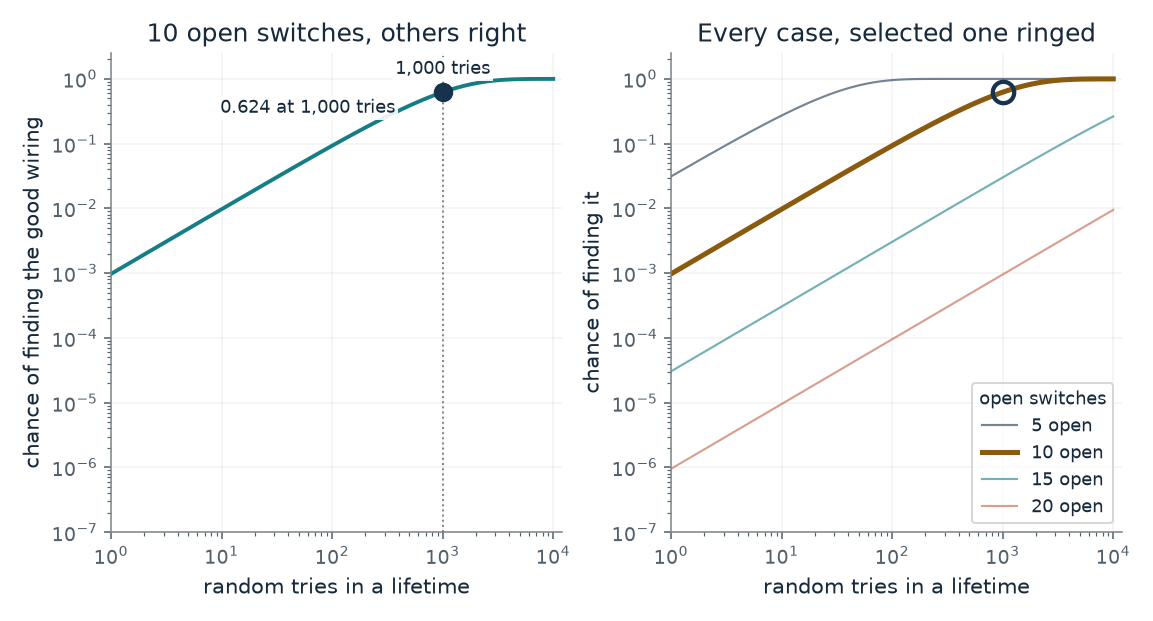

- **Chance of finding it:** 0.624
- **Settings of the open switches:** 1,024
- **Tries for even odds:** 710
- **Wirings in all (20 switches):** 1,048,576

A creature with 10 open switches and all its fixed genes right finds the good wiring in up to 1,000 tries with chance 0.624. The chapter's two cases are 10 open switches (about 62 in 100) and 20 (under 1 in 1,000) at 1,000 tries.

P = 1 - (1 - 2^(-10))^1000 = 1 - (1 - 0.0009766)^1000 = 0.624. One random try on 20 switches succeeds with chance 2^(-20) = 9.54e-07.

In [2]:
figure, values, explanation = odds_picture(**{'open_switches': 10, 'tries': 1000})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How hard is it to stumble on the one good wiring?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Open switches (?) = 10, Tries in a lifetime = 1000: With 10 open switches, up to 1,000 tries find the good wiring about 62 times in 100. With 20 open switches the chance falls to under 1 in 1,000, since there are 1,048,576 settings to wander through and only 1,000 looks.

**Takeaway:** A few open switches make the good wiring easy to find in a lifetime, and many make it nearly hopeless, so both the number of open switches and the number of tries matter, and each extra open switch halves the chance of one try.

**Why it matters:** This is why learning could help evolution only for creatures whose inherited genes were mostly right. Choosing among creatures then rewards the ones whose open switches are few.

**In brains and behavior:** The brain side is a possibility: an inherited capacity to learn could smooth evolution's search. The simulation did not measure that process in brains.

**In machines:** In a machine search the same arithmetic gives the cost of random trials in a space with 2^k settings.

**Where it applies:** The creature's fixed genes are all right, each try sets every open switch independently at random, and tries are independent. A creature with a wrong fixed gene can never succeed.

**Check your understanding:** With 5 open switches and 100 tries, is finding the good wiring likely, and about how many tries give even odds?

<details><summary>Show the answer</summary>

Very likely: 1 - (31/32)^100 is about 0.96. Even odds need about 22 tries.

</details>

*Source: Chapter 26, Learning that no child inherited still changed who had children. Book arithmetic built on the chapter's setup (20 connections, one good wiring, up to 1,000 tries). The chapter gives the two cases, 10 open switches (about 62 in 100) and 20 (under 1 in 1,000); they are the book's arithmetic, not results in the Hinton and Nowlan paper. The other values are this companion's variations.*

## C26-D02: What happens to the genes when only the choosing of parents changes?

1,000 creatures each carry 20 genes of 1, 0 or ?. They learn by random tries, and the quick learners leave more children. What do the gene shares do over 50 generations, though nothing learned is written into a gene?

A creature with any 0 gene never finds the good wiring and gets the baseline weight. One with no 0 genes and few ? genes often finds it early, and the earlier the more weight. Parents are drawn in proportion to weight and cross their genes, so the 0 alleles are removed and the 1 alleles rise.

$$
w=1+\frac{19\,n}{G},\qquad n=G-t
$$

**Symbols:** w: a creature's weight as a parent; 1 if it never finds the good wiring; t: the try on which it first finds the good wiring; G: the tries available (1,000); n: tries left after the finding, which sets how much extra weight it earns

**Predict before looking:** Predict what happens to the share of 0 genes, and whether the ? genes disappear, though no learned setting reaches a gene.

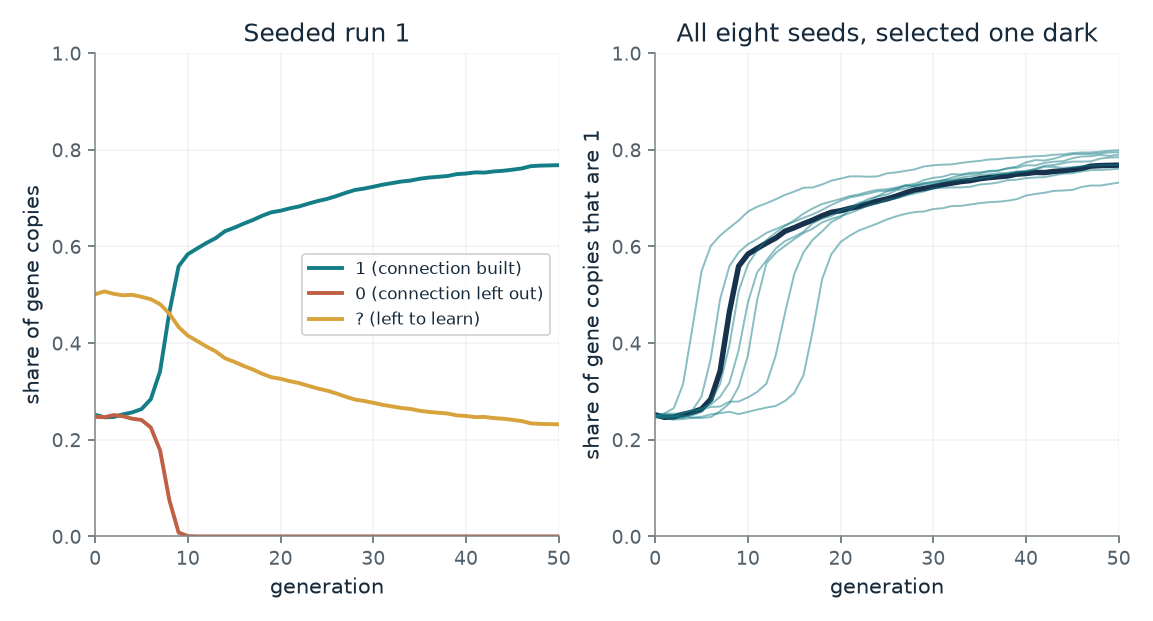

- **Share of 1 at generation 50:** 0.768
- **Share of 0 at generation 50:** 0
- **Share of ? at generation 50:** 0.232
- **Open switches per creature, start to end:** 10 to 4.64

In seeded run 1, the share of 1 genes goes from 0.252 to 0.768 in 50 generations and the share of 0 genes from 0.247 to 0, with no learned setting ever written into a gene. Many ? genes remain, so the good wiring is not yet inherited.

Each creature draws its first successful trial from a geometric law with chance 2^(-open switches), or never succeeds if any gene is 0. Parent weight = 1 + 19 n / 1000, n the trials left. Single-point crossover, no mutation, 1,000 creatures, 20 genes.

In [3]:
figure, values, explanation = baldwin_picture(**{'seed': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What happens to the genes when only the choosing of parents changes?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Seed of the run = 1: The share of 0 genes falls below 0.1 percent within about 10 generations in this seeded run (7 to 20 across the eight seeds; the chapter says about 20 for the paper's run) because a creature with a 0 gene can never find the good wiring, and 1 genes spread. The share of ? genes shrinks more slowly, and many remain at generation 50, so the right wiring is not yet inherited. The chapter says the paper's one shown run ended with about 56 percent of gene copies correct; these seeded runs end at 73 to 80 percent, so they are not a reproduction of that run.

**Takeaway:** Learning changed who had children, and that alone shifted the inherited genes toward the right settings, although every child started over.

**Why it matters:** This is the Baldwin effect in a toy: a trait that first needs learning can come to be built in. The chapter's caution is that the plotted run did not show the right wiring becoming fully innate.

**In brains and behavior:** A possibility, not a measurement: an inherited capacity to learn could smooth evolution's search.

**In machines:** The simulation is a specification of a search, with the reward for quick learners fixed by the experimenters.

**Where it applies:** Learning is the blunt rule in the chapter: random settings of the open switches on each try, frozen once the good wiring is found. Nothing learned is inherited. The case is extreme and unrealistic, as the authors say, and the simulation did not measure any process in brains. The paper does not fully specify some details, so the companion's choices may differ.

**Check your understanding:** Why does the share of 0 genes fall so much faster than the share of ? genes?

<details><summary>Show the answer</summary>

A single 0 gene rules a creature out of ever finding the good wiring, so selection removes 0 strongly. A ? gene only lowers the chance of finding it, and the effect fades as other ? genes become 1, so ? genes go away slowly.

</details>

*Source: Chapter 26, Learning that no child inherited still changed who had children. Seeded reimplementation by this companion, built from the chapter's description of Hinton and Nowlan (1987): 1,000 creatures, 20 genes started at 1, 0 or ? with chances a quarter, a quarter and a half, up to 1,000 random tries, parent weight 1 + 19n/1000, single-point crossover, no mutation. Eight seeded runs. It is not the authors' code, and the paper shows one typical run without a run count, so these runs are not a reproduction of its figure.*

## C26-D03: How often does the right wiring end up fully built in?

Run the 1987 simulation until the correct wiring fixes in every creature, or until a wrong or open setting fixes and the right wiring becomes impossible. How often does it fix, and does the number of tries matter?

Each run follows the population until some position is fixed. If every position is fixed on 1 the run is a success. If some position is fixed on a 0 or a ? the right wiring cannot become innate without mutation, so the run is a failure. The share of successes estimates the chance of full fixation.

$$
\hat p=\frac{\text{runs where the right wiring fixed}}{\text{runs}}
$$

**Symbols:** p-hat: the share of runs in which every creature ends up carrying the right wiring; G: the trial budget per lifetime

**Predict before looking:** Predict whether more tries per lifetime always raise the share of runs that end with the right wiring built in.

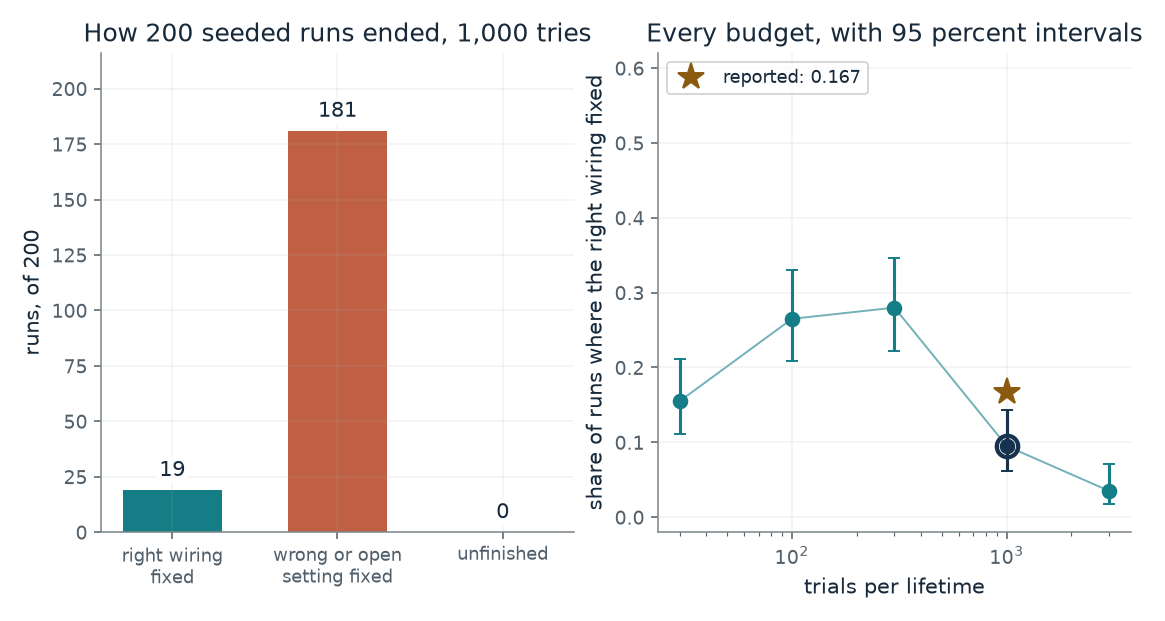

- **Right wiring fixed:** 19 of 200
- **Share (95 percent interval):** 0.095 (0.062 to 0.14)
- **Mean generations per run:** 492
- **Reported at 1,000 tries:** 0.167 (16.7 percent)

With 1,000 trials per lifetime, the right wiring fixed in 19 of 200 seeded runs, a share of 0.095. The chapter reports 0.167 at 1,000 trials for Fontanari and Santos; this reimplementation is not their code, so close agreement is not claimed. The interval excludes 0.167: this run does not reproduce that share.

Share = 19 / 200 = 0.095. 95 percent Wilson interval 0.0617 to 0.144, which treats the runs as independent.

In [4]:
figure, values, explanation = fixation_picture(**{'tries': 1000})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How often does the right wiring end up fully built in?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Trials per lifetime = 1000: At 1,000 tries the right wiring fixed in 19 of 200 seeded runs, about 1 in 10, clearly below the chapter's reported 16.7 percent: the 95 percent interval, about 0.06 to 0.14, does not include 0.167. This reimplementation does not reproduce that share, which is expected: it is built from a description, and model details the chapter and the paper do not fully specify, such as how parents are paired, can move the share. That is no claim about the chapter's own rerun or the paper's result. More tries are not always better: 100 and 300 tries fixed it more often, about 0.27, and 3,000 less often.

**Takeaway:** With learning, the right wiring fixed in roughly one run in ten here and about one in six in the chapter's report, against an estimated 1 in 10 million without it (a figure from Fontanari and Santos's fitted curve, not computed here). This reimplementation does not reproduce the chapter's one in six. How often it fixes depends on settings such as the trial budget.

**Why it matters:** The 1987 plot showed learning being selected, not the right wiring becoming innate. Counting how runs end is the test the chapter says Fontanari and Santos applied.

**In brains and behavior:** A model of evolution, not a measurement of any brain.

**In machines:** A search with a fixed supply of variation: no mutation, so a version of a gene missing from the first generation could never appear.

**Where it applies:** Runs stop as soon as a wrong or open setting fixes at any position (a failure) or the right wiring fixes everywhere (a success); a 20,000-generation cap would count as unfinished. The intervals treat the 200 runs as independent. For budgets other than 1,000 the weight is 1 + 19n/G, which is the companion's choice.

**Check your understanding:** Why would a run be counted as a failure if every creature carries a ? at one position, even though many creatures learn the good wiring?

<details><summary>Show the answer</summary>

With no mutation, the ? at that position cannot become a 1 by crossover, since every parent carries ?. The wiring can still be learned but is never fully inherited, which is the outcome the test excludes.

</details>

*Source: Chapter 26, Running the 1987 simulation to the end: about one run in six. Seeded reimplementation by this companion (200 runs per budget, the same rules as the previous demonstration), compared with the value the chapter reports from Fontanari and Santos (2017): 16.7 percent with learning at 1,000 trials, and an estimated 1 in 10 million without learning, read from a fitted curve. The chapter says the book's own rerun gave 0.164 (standard error 0.004); this reimplementation is not that rerun and has not been tuned to match. A second independent reimplementation made by the accuracy reviewer gave about 0.09 to 0.12 at 1,000 tries; the cause of the difference from 0.167 was not found.*

## C26-D04: How much of a change in the average came from choosing, and how much from copying?

Four seeds have hook lengths 0, 1, 2 and 3 mm and leave 1, 1, 2 and 2 seedlings. D's seedlings come out 0.3 mm shorter than D. How much does the average hook change, and from which source?

The covariance of offspring with trait is how much the seeds with more offspring differ in hook length, scaled by the average offspring. The second term averages how much seedlings differ from their parents, weighted by the offspring each seed leaves. Together they are the whole change.

$$
\Delta\bar z=\underbrace{\frac{\operatorname{Cov}(w,z)}{\bar w}}_{\text{choosing}}+\underbrace{\frac{\operatorname{E}(w\,\Delta z)}{\bar w}}_{\text{copying}}
$$

**Symbols:** z: a seed's trait (hook length in mm); w: offspring left by that seed; w-bar: the average offspring; Delta z: how a seedling's trait differs from its parent's

**Predict before looking:** Predict the sign of the net change when D's seedlings come out 0.3 mm shorter, and whether it is bigger or smaller than choosing alone.

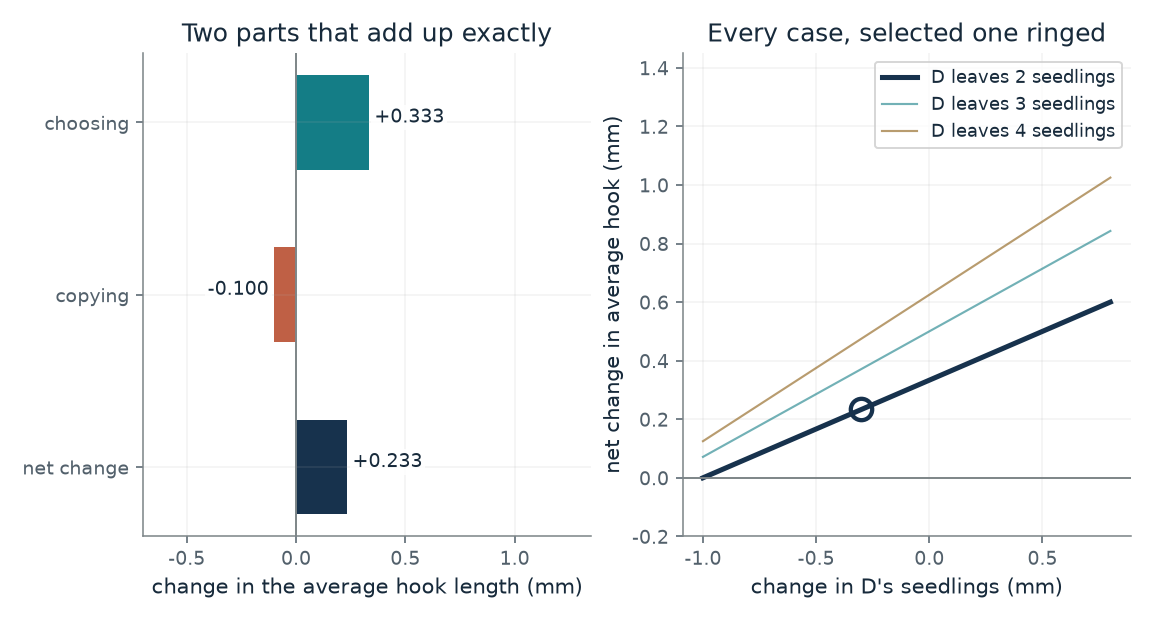

- **Choosing:** +0.333 mm
- **Copying:** -0.100 mm
- **Net change:** +0.233 mm
- **Average hook, before to after:** 1.50 to 1.73 mm

Choosing lifts the average hook by 0.333 mm, copying changes it by -0.100 mm, and the net is +0.233 mm. The two parts add up exactly to the change in the average.

Mean offspring = 1.500. Choosing = Cov(offspring, hook) / mean offspring = 0.333. Copying = average of (offspring x change in hook) / mean offspring = -0.100. Sum = +0.233.

In [5]:
figure, values, explanation = price_picture(**{'shift_d': -0.3, 'offspring_d': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much of a change in the average came from choosing, and how much from copying?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Change in D's seedlings (mm) = -0.3, Seedlings D leaves = 2: Choosing alone lifts the average hook by one third, from 1.5 to about 1.83 mm. D's shorter seedlings pull it down by 0.1. The net rise is about 0.23 mm, and the two parts add up exactly.

**Takeaway:** Choosing reweights the seeds the field already holds, while copying changes what the seedlings are, and the two add exactly to the change in the average.

**Why it matters:** A change in what a pool holds can come from picking among candidates or from making new ones. A search that only picks can never leave what the pool already contains.

**In brains and behavior:** Price's identity is bookkeeping for any trait, including genes. It says nothing about how a brain learns.

**In machines:** In a model search, choosing is the rule that keeps high-scoring candidates and copying is the variation that proposes new ones.

**Where it applies:** One generation, a fixed list of seeds, and copying changes only for D's seedlings. The split is an exact bookkeeping identity for any trait, so it describes the change without explaining a mechanism.

**Check your understanding:** If D left 3 seedlings and its seedlings came out 0.3 mm shorter, what is the net change?

<details><summary>Show the answer</summary>

Choosing is 0.5 (offspring 1, 1, 2, 3; mean 1.75) and copying is 3 x (minus 0.3) / 4 / 1.75 = minus 0.129, so the net is about plus 0.371 mm.

</details>

*Source: Chapter 26, A field of seeds, and a striped seed that stays at zero. Book formula and worked example (George Price's 1970 split). The chapter's four-seed field and its numbers (choosing 1/3, copying minus 0.1, net about 0.23) are reproduced at the reveal state. The other shifts and offspring counts for D are this companion's variations.*

## C26-D05: Why does a seed the field does not hold never appear by choosing?

A field has round, wrinkled and speckled seeds leaving 1, 2 and 4 offspring each, and no striped seeds, which would leave 10. What does one round of choosing do, and what would bring striped seeds in?

Multiply each kind's share by its offspring and divide by the total so the shares add to one again. Striped has a share of zero, so its product is zero and its next share is zero. Moving some speckled offspring into striped each round puts a nonzero share in, after which striped's 10 offspring let it spread.

$$
x_i'=\frac{x_i\,f_i}{\sum_j x_j\,f_j}
$$

**Symbols:** x_i: the share of kind i now; x_i': its share next round; f_i: the offspring left by each member of kind i

**Predict before looking:** Predict the striped share after one round, then after 12, when it starts at zero and nothing copies it in.

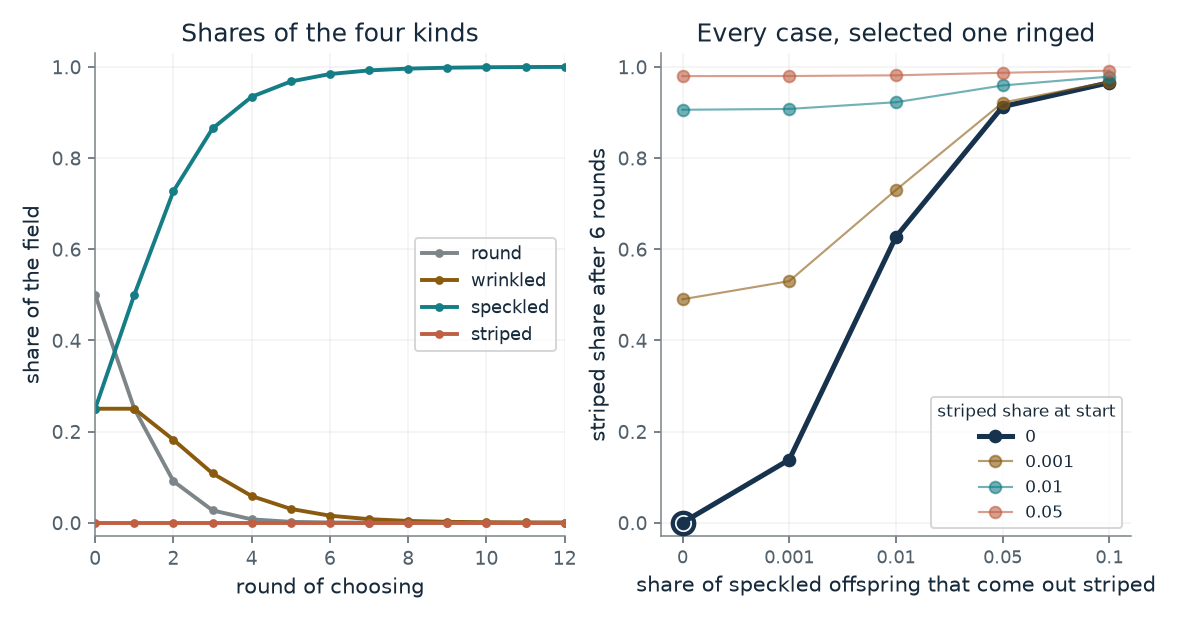

- **After round 1 (round, wrinkled, speckled, striped):** 0.25, 0.25, 0.5, 0
- **Striped share after 12 rounds:** 0
- **Round share after 12 rounds:** 1.19e-07

Round falls to a quarter, wrinkled holds at a quarter, speckled doubles to a half, and striped stays at zero however well it would have done. Zero times anything is zero, so no number of rounds brings it back.

New share = share x offspring / sum of (share x offspring). From (0.5, 0.25, 0.25, 0) with offspring (1, 2, 4, 10): products 0.5, 0.5, 1.0, 0, total 2, new shares 0.25, 0.25, 0.5, 0. The copy-error step is this companion's addition.

In [6]:
figure, values, explanation = replicator_picture(**{'copy_error': 0.0, 'start_striped': 0.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does a seed the field does not hold never appear by choosing?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Speckled offspring that come out striped = 0.0, Striped share at the start = 0.0: One round gives round 0.25, wrinkled 0.25, speckled 0.5 and striped 0. Zero times anything is zero, so striped stays at zero however many rounds pass. With a small copy error or a small starting share, it takes over within a dozen rounds.

**Takeaway:** Choosing can only reweight what the pool holds. A kind with a share of zero stays at zero, and even a tiny nonzero share can take over if its offspring are numerous.

**Why it matters:** A search that picks among candidates needs a source of candidates. In 1987 the starting pool already held the right piece at every position, so learning only had to help choosing combine them.

**In brains and behavior:** Nothing here measures a brain. The replicator rule keeps the books for a pool without showing the mechanisms match.

**In machines:** In the merge search, the random nudges and the people who chose the sources supply the candidates.

**Where it applies:** A fixed list of kinds and a positive total. Choosing alone, with no copy error, cannot add a kind. A nonzero starting share or a copy error changes that. The step form does not show that any real mechanism matches the arithmetic.

**Check your understanding:** If striped starts at 0.01 with no copy error, does it ever appear in the next round's shares, and does it take over?

<details><summary>Show the answer</summary>

Yes: its share is 0.01 x 10 divided by the new total, about 0.048 after one round, and it grows each round and takes over within a dozen. Starting above zero matters.

</details>

*Source: Chapter 26, A field of seeds, and a striped seed that stays at zero. Book formula (the replicator rule in its step form, from Taylor and Jonker 1978) and constructed ledger: shares 0.5, 0.25, 0.25 and 0, offspring 1, 2, 4 and 10, which hold no real data. The copy-error step, where some speckled offspring come out striped, and the nonzero starting shares are this companion's variations, in the spirit of the chapter's note that variation in copying can introduce a missing type.*

## C26-D06: How much should a 52 percent score on 250 problems be trusted?

A search merged three models into one that scored 52.0 percent on 250 held-out Japanese math problems, against 9.6, 18.4 and 30.0 for the sources. What do the scores say, and what could a 250-problem test tell apart?

Each score is a share of 250 problems. A test of that size can only separate scores that differ by more than about the width of the bars, which is wider for small tests and for scores near one half. The merge's lead over its best source is much larger than that width at 250 problems.

$$
\text{problems correct}=\frac{\text{percent}}{100}\times 250
$$

**Symbols:** 250: the held-out test problems, kept out of the 1,069 that drove the search; 95 percent bar: the Wilson interval for a score if the problems were a random sample of a larger pool (the companion's addition)

**Predict before looking:** Predict the smallest test size at which the interval around the merge no longer overlaps the best source's.

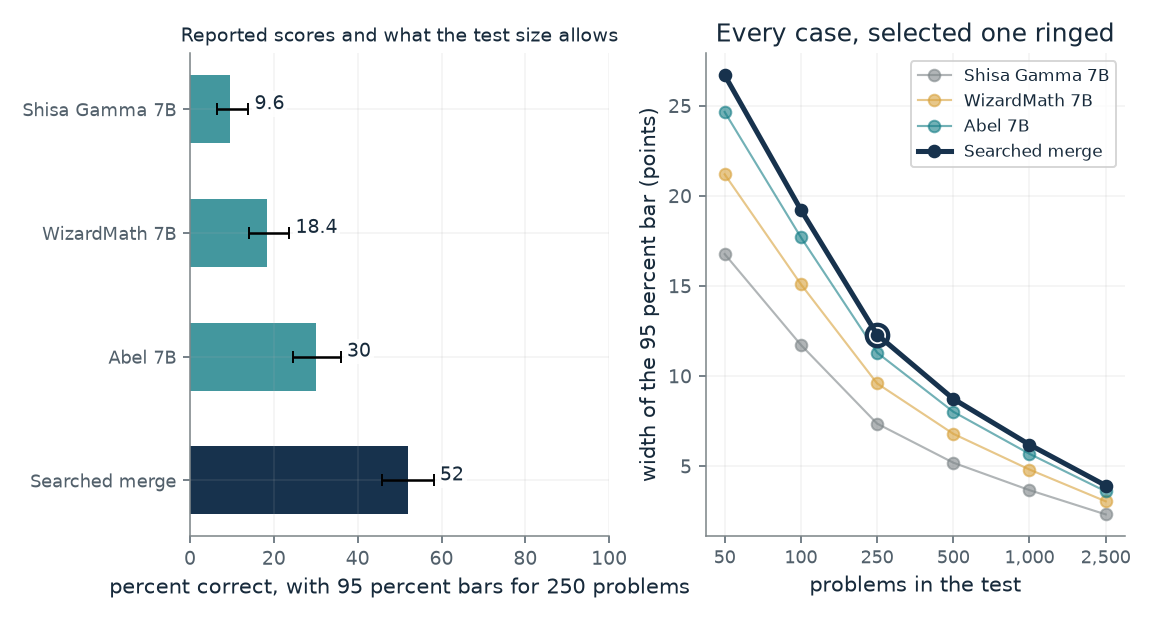

- **Reported score:** 52 percent
- **Problems correct at 250:** 130 of 250
- **95 percent bar at 250 problems:** 45.8 to 58.1
- **Merge bar clear of the best source's?:** yes

Searched merge scored 52 percent, which is 130 of 250 problems. If the test problems were a random sample, a test of 250 would put its score between 45.8 and 58.1. The bars say nothing about the people who chose the sources, the method and the test.

52 percent of 250 = 130 problems. Wilson 95 percent bar at n = 250: 45.8 to 58.1. Merge 52.0 against the best source 30.0: separated at this size.

In [7]:
figure, values, explanation = merge_picture(**{'model': 'merge', 'test_size': 250})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much should a 52 percent score on 250 problems be trusted?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which model = merge, Problems in the test = 250: The merge's 52.0 is 130 of 250. At 250 problems its 95 percent bar, roughly 46 to 58, sits clear of the best source's, roughly 25 to 36. With 50 problems the bars overlap, and they separate by 100. The bars show only how finely a test of that size can tell; they say nothing about who chose the sources, the method and the test.

**Takeaway:** Sampling alone does not explain the gap between 52.0 and 30.0 on 250 problems, but the result still depends on what people supplied and on one test.

**Why it matters:** A search can explore recipes and score them, but it cannot find a candidate outside the space it was allowed to try. A person can change that space or the test while the machine explores the alternatives.

**In brains and behavior:** No brain is involved. The sources, the search space and the test were all chosen by people.

**In machines:** The search used a random-sampling method (CMA-ES) around a changing center, scored each candidate on the 1,069 training problems, and checked the chosen recipe on the 250 held-out ones.

**Where it applies:** One test, in one language. People chose the three sources, the merging method and the test. The intended criterion needed a correct number and Japanese reasoning, scored by imperfect automatic checks. If designers kept changing recipes after seeing the 250 answers, that set would become part of selection. The bars treat the problems as a random sample, which they are not.

**Check your understanding:** How many of the 250 problems did the best source get right, and is the merge's lead there beyond the sampling bars?

<details><summary>Show the answer</summary>

30.0 percent of 250 is 75 problems, against 130 for the merge. The merge's lower bar (about 46) is above the best source's upper bar (about 36), so sampling alone does not explain the lead. Other limits remain.

</details>

*Source: Chapter 26, A search merged three models into a better one. Reported scores quoted in the chapter from Akiba and colleagues (2025): the three sources scored 9.6, 18.4 and 30.0, and the merge the paper labels PS scored 52.0 on 250 test problems, after 1,000 trials of CMA-ES on 1,069 training problems. The counts correct and the sampling bars are this companion's arithmetic. No simulation.*

## Bring it to your own question

Ask who supplied the candidates, who said which was good, and whether the test that picked the winner is separate from the test that reports it. Use the odds card for how hard a single good setting is to find, the choosing-and-copying split to see whether a change came from reweighting what was there or from new variation, and the replicator card to check whether the best kind was in the pool at all. Report the score with the size of the test and the choices people made.

Use the `mmi-ch26-starting-structure` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.